# Импорты и путь к src

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from metrics import build_test_targets, evaluate_model
from baselines import popularity_baseline, last_item_baseline

pd.set_option('display.max_columns', None)

### Загрузка сплитов

In [2]:
train = pd.read_parquet("../data/processed/train.parquet")
test =  pd.read_parquet("../data/processed/test.parquet")
val =  pd.read_parquet("../data/processed/val.parquet")

In [3]:
print(f"Train: {len(train):>10,} | {train['last_watch_dt'].min().date()} -> {train['last_watch_dt'].max().date()}")
print(f"Val:   {len(val):>10,} | {val['last_watch_dt'].min().date()} -> {val['last_watch_dt'].max().date()}")
print(f"Test:  {len(test):>10,} | {test['last_watch_dt'].min().date()} -> {test['last_watch_dt'].max().date()}")

print("\nЮзеров в train:", train['user_id'].nunique())
print("Юзеров в test: ", test['user_id'].nunique())
print("Айтемов в train:", train['item_id'].nunique())
print("Айтемов в test: ", test['item_id'].nunique())

Train:  3,787,046 | 2021-03-13 -> 2021-07-23
Val:      371,021 | 2021-07-24 -> 2021-08-03
Test:     474,130 | 2021-08-04 -> 2021-08-22

Юзеров в train: 727645
Юзеров в test:  132323
Айтемов в train: 14935
Айтемов в test:  7717


### Таргеты для оценки

In [4]:
test_targets = build_test_targets(test, one_per_user=True)

print(f"Таргетов для оценки: {len(test_targets):,}")
print(f"Уникальных юзеров:   {test_targets['user_id'].nunique():,}")
print(f"Уникальных айтемов:  {test_targets['item_id'].nunique():,}")

test_targets.head()

Таргетов для оценки: 132,323
Уникальных юзеров:   132,323
Уникальных айтемов:  5,062


,user_id,item_id
0,753034,15297
1,289921,7829
2,644912,3819
3,646908,6809
4,30279,12192


**Топ айтемов**

In [5]:
popular_series = (train.groupby('item_id')
                       .size()
                       .sort_values(ascending=False))
print("Топ-10 популярных айтемов и число взаимодействий:")
print(popular_series.head(10))
print(f"\nВсего айтемов в train: {len(popular_series):,}")

Топ-10 популярных айтемов и число взаимодействий:
item_id
10440    143231
15297    138750
13865     94367
9728      78750
4151      70200
2657      55521
3734      50991
4880      44308
142       35917
6809      32802
dtype: int64

Всего айтемов в train: 14,935


**Популярность: оценка**

In [6]:
pop_predict = popularity_baseline(train, top_n=200)
pop_metrics = evaluate_model(pop_predict, test_targets)

print("\nPopularity Baseline")
for k, v in pop_metrics.items():
    print(f"{k:>12s}: {v:.4f}")

  обработано 10,000/132,323
  обработано 20,000/132,323
  обработано 30,000/132,323
  обработано 40,000/132,323
  обработано 50,000/132,323
  обработано 60,000/132,323
  обработано 70,000/132,323
  обработано 80,000/132,323
  обработано 90,000/132,323
  обработано 100,000/132,323
  обработано 110,000/132,323
  обработано 120,000/132,323
  обработано 130,000/132,323

Popularity Baseline
   Recall@10: 0.1685
     NDCG@10: 0.0931
      MAP@10: 0.0696
   Recall@50: 0.2892
     NDCG@50: 0.1190
      MAP@50: 0.0747
  Recall@100: 0.3574
    NDCG@100: 0.1302
     MAP@100: 0.0757


**Last-item: оценка**

In [7]:
last_predict = last_item_baseline(train, top_n=200)
last_metrics = evaluate_model(last_predict, test_targets)

print("\n=== Last-Item Baseline ===")
for k, v in last_metrics.items():
    print(f"{k:>12s}: {v:.4f}")

  обработано 10,000/132,323
  обработано 20,000/132,323
  обработано 30,000/132,323
  обработано 40,000/132,323
  обработано 50,000/132,323
  обработано 60,000/132,323
  обработано 70,000/132,323
  обработано 80,000/132,323
  обработано 90,000/132,323
  обработано 100,000/132,323
  обработано 110,000/132,323
  обработано 120,000/132,323
  обработано 130,000/132,323

=== Last-Item Baseline ===
   Recall@10: 0.1662
     NDCG@10: 0.0745
      MAP@10: 0.0459
   Recall@50: 0.2892
     NDCG@50: 0.1008
      MAP@50: 0.0512
  Recall@100: 0.3566
    NDCG@100: 0.1118
     MAP@100: 0.0522


### Сводная таблиа результатов

In [8]:
results = pd.DataFrame({
    'Popularity': pop_metrics,
    'Last-Item':  last_metrics,
})
results.index.name = 'metric'
print(results.round(4))

# Созранение для последующего сравнения с результатами GPT-2
results.to_csv('../results/baselines_metrics.csv')
print("\nСохранено в results/baselines_metrics.csv")

            Popularity  Last-Item
metric                           
Recall@10       0.1685     0.1662
NDCG@10         0.0931     0.0745
MAP@10          0.0696     0.0459
Recall@50       0.2892     0.2892
NDCG@50         0.1190     0.1008
MAP@50          0.0747     0.0512
Recall@100      0.3574     0.3566
NDCG@100        0.1302     0.1118
MAP@100         0.0757     0.0522

Сохранено в results/baselines_metrics.csv


### Визуализация

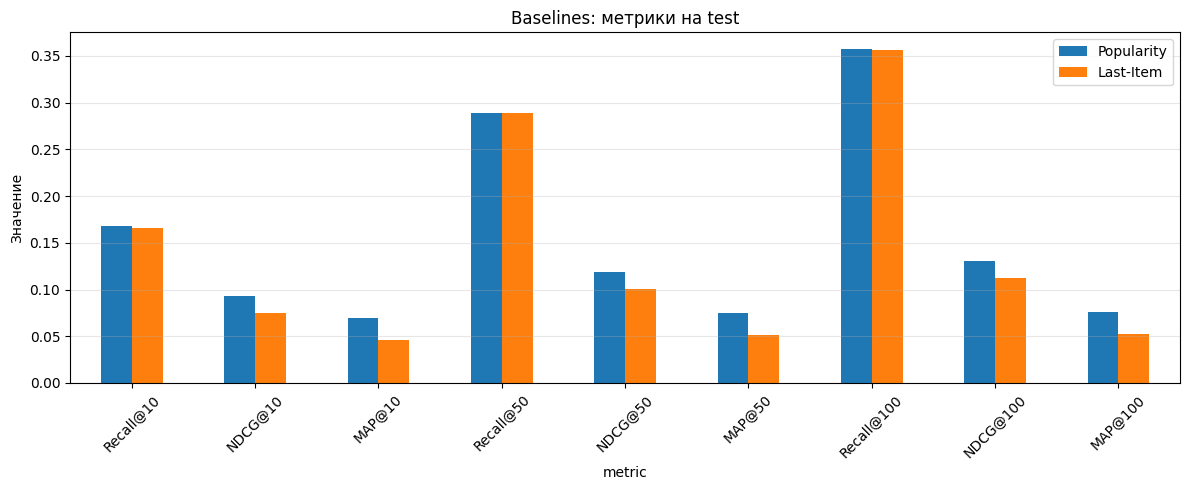

In [9]:
ax = results.plot(kind='bar', figsize=(12, 5), rot=45)
ax.set_title('Baselines: метрики на test')
ax.set_ylabel('Значение')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../results/baselines_metrics.png', dpi=100)
plt.show()